In [1]:
import numpy as np

# Made-up toy data: hours of safety training per worker (x) vs. TRIR (y).
# Five points on purpose, so every number can be checked by hand
x = np.array([2, 4, 6, 8, 10], dtype=float)
y = np.array([7, 6, 4, 3, 1], dtype=float)


def mse(y_true: np.ndarray, y_pred: np.ndarray) -> float:
    """Average of (prediction - actual) squared."""
    return np.mean((y_pred - y_true) ** 2)


# A guessed line: start at 7 and drop half a point of TRIR per training hour
w, b = -0.5, 7.0
y_pred = w * x + b
print(mse(y, y_pred))

0.6


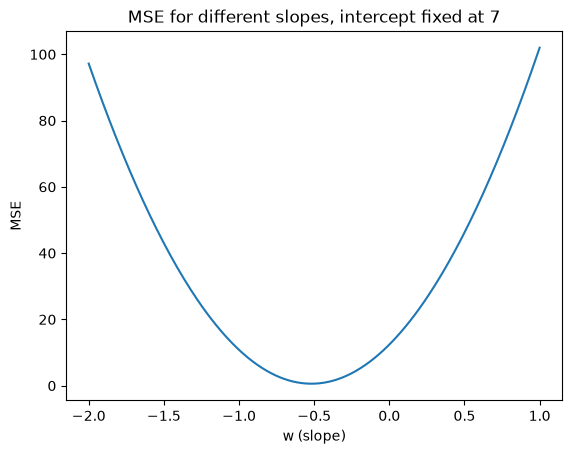

In [2]:
import matplotlib.pyplot as plt

# Keep the intercept fixed so we can see loss change along one weight at a time
b_fixed = 7.0
w_values = np.linspace(-2, 1, 200)
losses = [mse(y, w_try * x + b_fixed) for w_try in w_values]

plt.plot(w_values, losses)
plt.xlabel("w (slope)")
plt.ylabel("MSE")
plt.title("MSE for different slopes, intercept fixed at 7")
plt.show()

In [3]:
def gradient_descent(x, y, learning_rate=0.01, steps=5000):
    # Start from a flat line at zero; gradient descent will walk it downhill
    w, b = 0.0, 0.0

    for step in range(steps):
        y_pred = w * x + b
        error = y_pred - y

        grad_w = np.mean(2 * error * x)
        grad_b = np.mean(2 * error)
        w = w - learning_rate * grad_w
        b = b - learning_rate * grad_b

    return w, b


w_gd, b_gd = gradient_descent(x, y)
print(f"w = {w_gd:.3f}, b = {b_gd:.3f}, MSE = {mse(y, w_gd * x + b_gd):.3f}")

w = -0.750, b = 8.700, MSE = 0.060


In [4]:
# Same starting point every time, just more steps, so you can watch the line walk downhill
for n_steps in [1, 10, 100, 1000, 5000]:
    w_s, b_s = gradient_descent(x, y, steps=n_steps)
    print(f"{n_steps:>5} steps: w = {w_s:7.3f}, b = {b_s:6.3f}, MSE = {mse(y, w_s * x + b_s):.3f}")

    1 steps: w =   0.384, b =  0.084, MSE = 13.631
   10 steps: w =   0.392, b =  0.363, MSE = 12.699
  100 steps: w =   0.077, b =  2.657, MSE = 6.700
 1000 steps: w =  -0.717, b =  8.458, MSE = 0.071
 5000 steps: w =  -0.750, b =  8.700, MSE = 0.060


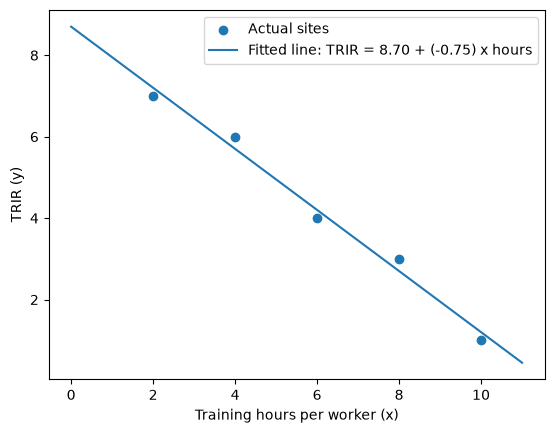

In [5]:
# The five toy sites as dots, plus the line gradient descent found
plt.scatter(x, y, label="Actual sites")

# Start the line at x = 0 so you can see where it begins
x_line = np.linspace(0, 11, 100)
plt.plot(x_line, b_gd + w_gd * x_line, label=f"Fitted line: TRIR = {b_gd:.2f} + ({w_gd:.2f}) x hours")

plt.xlabel("Training hours per worker (x)")
plt.ylabel("TRIR (y)")
plt.legend()
plt.show()

In [6]:
# One row per site: a column of 1s (pairs with b), then training hours (pairs with w)
X = np.column_stack([np.ones_like(x), x])

# Same order as X's columns: b first, then w
theta = np.array([b_gd, w_gd])

print(X)

# TODO: print the predictions for all five sites in one line using @
print (X @ theta)

[[ 1.  2.]
 [ 1.  4.]
 [ 1.  6.]
 [ 1.  8.]
 [ 1. 10.]]
[7.19999989 5.69999993 4.19999997 2.70000001 1.20000005]


In [8]:
def normal_equation(X, y):
    """Jump straight to the bottom of the bowl: theta = (X^T X)^-1 X^T y."""
    # TODO: one line. np.linalg.inv() inverts a matrix, .T transposes, @ multiplies
    return np.linalg.inv(X.T @ X) @ X.T @ y

theta_ne = normal_equation(X, y)
print(theta_ne)

[ 8.7  -0.75]
